# Task 1: Data Preprocessing

In [51]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

SEED = 42
TELCO_PATH   = "/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"
HOUSING_PATH = "/kaggle/input/datasets/camnugent/california-housing-prices/housing.csv"

# Telco churn, look at the data

In [52]:
df = pd.read_csv(TELCO_PATH)
print(df.shape)
print(df.dtypes)
df.head()

(7043, 21)
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Missing values

In [53]:
print(df.isna().sum().sum(), "real NaN values")                 

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")   
print(df["TotalCharges"].isna().sum(), "missing after converting")

df[df["TotalCharges"].isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

0 real NaN values
11 missing after converting


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [54]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["TotalCharges"].isna().sum() 

np.int64(0)

## Duplicates

In [55]:
print("full-row duplicates:", df.duplicated().sum())
print("same profile, different customerID:", df.drop(columns="customerID").duplicated().sum())

full-row duplicates: 0
same profile, different customerID: 22


## Skewness

tenure            0.24
MonthlyCharges   -0.22
TotalCharges      0.96
dtype: float64


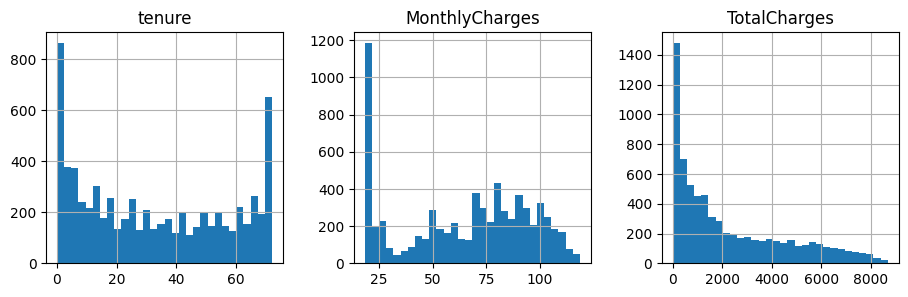

In [56]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
print(df[num_cols].skew().round(2))
df[num_cols].hist(figsize=(11, 3), bins=30, layout=(1, 3))
plt.show()

In [57]:
print(df["tenure"].min(), df["TotalCharges"].min())

0 0.0


## Outliers

In [58]:
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[c] < low) | (df[c] > high)).sum()
    print(f"{c}: {n} outliers (bounds {low:.1f} to {high:.1f})")
    df[c] = df[c].clip(low, high)

tenure: 0 outliers (bounds -60.0 to 124.0)
MonthlyCharges: 0 outliers (bounds -46.0 to 171.4)
TotalCharges: 0 outliers (bounds -4683.5 to 8868.7)


## Class balance

In [59]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


## Feature engineering and split	

In [60]:
from sklearn.model_selection import train_test_split

df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
df = df.drop(columns="customerID")
df["tenure_group"] = pd.qcut(df["tenure"], 4, labels=["q1", "q2", "q3", "q4"])

X = pd.get_dummies(df.drop(columns="Churn"), drop_first=True)
y = df["Churn"]
print(X.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape, round(y_train.mean(), 3), round(y_test.mean(), 3))

(7043, 33)
(5634, 33) (1409, 33) 0.265 0.265


## Scale and balance the training set

In [61]:
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

scaler = StandardScaler()
scaler.fit(X_train)

train_scaled_array = scaler.transform(X_train)
test_scaled_array = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(train_scaled_array, columns=X.columns)
X_test_scaled = pd.DataFrame(test_scaled_array, columns=X.columns)

churners_before = int(y_train.sum())
print("churners in train before SMOTE:", churners_before)

smote = SMOTE(random_state=SEED)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

churners_after = int(y_train_balanced.sum())
print("churners in train after SMOTE:", churners_after)

churners in train before SMOTE: 1495
churners in train after SMOTE: 4139


# Part B California housing, Look at the data

In [62]:
housing = pd.read_csv(HOUSING_PATH)
print(housing.shape)
housing.info()

(20640, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


## Missing values

In [63]:
missing_per_column = housing.isna().sum()
print(missing_per_column[missing_per_column > 0])

total_bedrooms    207
dtype: int64


In [64]:
median_bedrooms = housing["total_bedrooms"].median()
print("median used for the fill:", median_bedrooms)

housing["total_bedrooms"] = housing["total_bedrooms"].fillna(median_bedrooms)
print("missing after fill:", housing["total_bedrooms"].isna().sum())

median used for the fill: 435.0
missing after fill: 0


## Duplicates

In [65]:
duplicate_rows = housing.duplicated().sum()
print("duplicate rows:", duplicate_rows)

housing = housing.drop_duplicates()
print(housing.shape)

duplicate rows: 0
(20640, 10)


## Feature engineering and skewness	

In [66]:
housing["rooms_per_household"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_per_room"] = housing["total_bedrooms"] / housing["total_rooms"]
housing["people_per_household"] = housing["population"] / housing["households"]

In [67]:
target_name = "median_house_value"
columns_to_skip = [target_name, "longitude", "latitude"]      

numeric_columns = [c for c in housing.select_dtypes("number").columns if c not in columns_to_skip]
print(housing[numeric_columns].skew().round(2).sort_values(ascending=False))

people_per_household    97.64
rooms_per_household     20.70
bedrooms_per_room        6.32
population               4.94
total_rooms              4.15
total_bedrooms           3.48
households               3.41
median_income            1.65
housing_median_age       0.06
dtype: float64


In [68]:
for column in numeric_columns:
    column_skew = housing[column].skew()
    if column_skew > 1:
        housing[column] = np.log1p(housing[column])
        print("log1p applied to", column, "(skew was", round(column_skew, 2), ")")

print(housing[numeric_columns].skew().round(2).sort_values(ascending=False))

log1p applied to total_rooms (skew was 4.15 )
log1p applied to total_bedrooms (skew was 3.48 )
log1p applied to population (skew was 4.94 )
log1p applied to households (skew was 3.41 )
log1p applied to median_income (skew was 1.65 )
log1p applied to rooms_per_household (skew was 20.7 )
log1p applied to bedrooms_per_room (skew was 6.32 )
log1p applied to people_per_household (skew was 97.64 )
people_per_household    3.88
bedrooms_per_room       2.80
rooms_per_household     1.39
median_income           0.23
housing_median_age      0.06
total_bedrooms         -1.00
population             -1.04
households             -1.05
total_rooms            -1.08
dtype: float64


##  Outliers

In [69]:
for column in numeric_columns:
    q1, q3 = housing[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    count_outside = ((housing[column] < lower_bound) | (housing[column] > upper_bound)).sum()
    housing[column] = housing[column].clip(lower_bound, upper_bound)
    print(f"{column}: {count_outside} values capped")

price_ceiling = housing[target_name].max()
share_at_ceiling = (housing[target_name] == price_ceiling).mean()
print("target maximum:", price_ceiling, "| share of districts at that value:", round(share_at_ceiling, 3))

housing_median_age: 0 values capped
total_rooms: 957 values capped
total_bedrooms: 836 values capped
population: 848 values capped
households: 882 values capped
median_income: 226 values capped
rooms_per_household: 523 values capped
bedrooms_per_room: 578 values capped
people_per_household: 470 values capped
target maximum: 500001.0 | share of districts at that value: 0.047


##  Class balance

the target is a number, not categories, and so there are no classes to balance.

##  Encode, split, scale

In [70]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_house = pd.get_dummies(housing.drop(columns=target_name), columns=["ocean_proximity"], drop_first=True)
y_house = housing[target_name]
print(X_house.shape)

X_house_train, X_house_test, y_house_train, y_house_test = train_test_split(
    X_house, y_house, test_size=0.2, random_state=SEED)
print(X_house_train.shape, X_house_test.shape)

(20640, 15)
(16512, 15) (4128, 15)


In [71]:
house_scaler = StandardScaler()
house_scaler.fit(X_house_train)                        

X_house_train_scaled = house_scaler.transform(X_house_train)
X_house_test_scaled = house_scaler.transform(X_house_test)
print(X_house_train_scaled.shape, X_house_test_scaled.shape)

(16512, 15) (4128, 15)
